# Beltrami Prior Tuning

`wCSET` can also be regularized with a purely geometric basis -- Laplace-Beltrami
eigenmodes of the cortical mesh (`mm.anatomy.source_space.compute_beltrami_harmonics`)
instead of the structural-connectome Laplacian (`compute_cst`) -- see
`../connectomic/beltrami_harmonics_notes.md` for the full design rationale (why this
basis needs its own orthonormalization, why hemispheres are independent, etc.).

Same `compute_harmonic_prior(method="lowpass")` weighting as the connectome side
(`weight = exp(-beta*eigval)`), but tuned separately: the mesh spectrum has a very
different shape (see the beta-sweep section below), so the connectome's settled
`beta=5` (`harmonic-prior-tuning.ipynb`) is not expected to transfer as-is.

Uses the same simulated `simf10` dataset (known ground truth) and the same
evaluation methodology as `harmonic-prior-tuning.ipynb`, runs 1-10, for direct
comparability.

## 🧪 - Experiment setup
- `fwd`: Forward solution
- `eigvec`/`eigval`: Mesh-Beltrami eigendecomposition of the source space's own
  cortex-only per-hemisphere mesh (`compute_beltrami_harmonics`) -- purely
  geometric, no connectome/connectivity input at all
- `runs`: simf10 runs to sweep over -- `ave`/`ncov`/`gold`/`source` are run-dependent
  and reloaded per run inside the main loop; everything else here is subject-level
  and loaded/computed once

In [1]:
# imports
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

import mindmap as mm
import mne

from mindmap.analysis.functional.inverse.utils import compute_harmonic_prior
from mindmap.analysis.functional.common.metric import find_peak_localization_error
from mindmap.analysis.simulation.engine import Simulator

# readers
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"
runs = [str(r) for r in range(1, 11)]

# subject-level data (run-independent)
fwd = dm.load(sub, "fwd", desc="inv")

# Mesh-Beltrami eigendecomposition -- purely geometric, no connectome input.
# Timing is load-dependent (seen 4s-110s across sessions, same variance the
# connectome's own eigh already shows -- see beltrami_harmonics_notes.md).
# No formal "eig"-style cache registered for this basis yet (only the
# connectome's `eig` datatype has one), so computed fresh here.
t0 = time.time()
eigvec, eigval = mm.anatomy.source_space.compute_beltrami_harmonics(fwd["src"])
print(f"mesh-Beltrami eigendecomposition: {time.time()-t0:.1f}s, shape={eigvec.shape}")

simulator, _, _ = Simulator.load(dm.roots["sim"]/f"sub-{sub}"/"simulator")
dipole_positions = mm.anatomy.source_space.get_dipole_positions(fwd["src"]) * 1000

# crop
tmin, tmax = -0.05, 0.15

mesh-Beltrami eigendecomposition: 4.3s, shape=(7465, 7464)


## 🎚️ - Beta sweep

The mesh-Beltrami spectrum has a very different shape from the connectome's:
connectome eigenvalues cluster near the top of their range (median 1.03 of max
1.61), while mesh eigenvalues are spread out with a long tail (median 0.25 of max
4.71, 90th percentile only 0.55). Reusing the connectome's own grid
(`[1,2,3,5,7,10]`) would barely suppress anything here -- at `beta=10` the mesh
basis still has an effective ~2,840 of 7,464 modes contributing (participation
ratio `(Σw)²/Σw²`), vs. the connectome's ~447 at its settled `beta=5`. Swept a
substantially wider grid instead, chosen (via the same participation-ratio check)
to bracket the point where mesh effective-DOF matches the connectome's own settled
operating point (participation ratio ≈447 lands around `beta≈50` on this
spectrum).

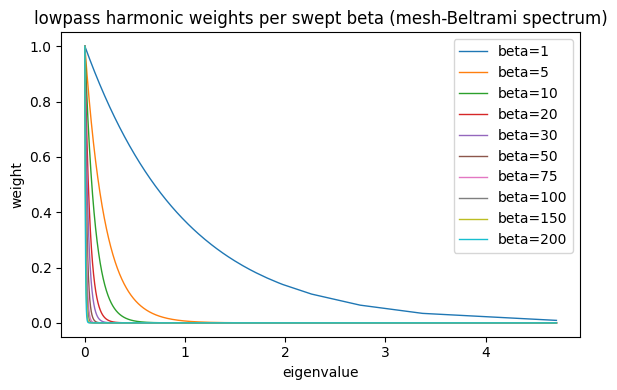

In [2]:
betas = [1, 5, 10, 20, 30, 50, 75, 100, 150, 200]

fig, ax = plt.subplots(figsize=(6, 4))
for beta in betas:
    w = compute_harmonic_prior(eigval, relaxation=beta, method="lowpass")
    ax.plot(eigval, w, lw=1, label=f"beta={beta}")
ax.set_xlabel("eigenvalue")
ax.set_ylabel("weight")
ax.set_title("lowpass harmonic weights per swept beta (mesh-Beltrami spectrum)")
ax.legend()
fig.tight_layout()

## 🎯 - Solve and evaluate across runs x betas

Same construction as `harmonic-prior-tuning.ipynb`: for each of `runs` x `betas`,
solve with `wCSET` (`harmonic_method="lowpass"`, `eigenvectors`/`eigenvalues` from
the mesh-Beltrami basis instead of the connectome), then score against that run's
own `gold`: spatial correlation over the whole cropped window, average precision
(AP) at half-rising-phase and peak-phase, and peak-localization-error at
half-rising-phase. Registered into `metrics` under `label=f"beta={beta}"`.

`sLORETA` solved once per run too (no `beta`, no basis at all) as an external
reference point, same as the connectome-side notebook.

In [3]:
metrics = mm.metric.MetricSuite(f"Beltrami Prior Tuning {sub} lowpass sweep")
scalar_rows = []

for run in tqdm(runs, desc="runs"):
    ave = dm.load(sub, "ave", run=run)
    ncov = dm.load(sub, "cov", run=run)
    gold = dm.load(sub, "gold", run=run)

    data = ave.copy().crop(tmin=tmin, tmax=tmax)
    ground = gold.copy().crop(tmin=tmin, tmax=tmax)

    snr, snr_db = mm.analysis.eeg.estimate_evoked_snr(evoked=ave, baseline=(-0.4, -0.2), noise_cov=ncov)
    lambda2 = max(0.01, 1.0 / (snr.max()**2))

    hrp = mm.analysis.eeg.get_rising_phase(data, ratio=0.5, as_idx=True)[0]
    pp = mm.analysis.eeg.get_rising_phase(data, ratio=1, as_idx=True)[0]

    src_seed = dm.load(sub, "source", run=run)
    true_source_mask = src_seed.select_targets(simulator.hm.src, simulator.hm.parc, simulator.hm.ras2tkras)

    def evaluate_and_register(label, sol):
        # spatial correlation over the whole cropped window
        corr = np.asarray(mm.analysis.inverse.compute_stc_correlation(ground, sol, mode="spatial", method="pearson"))
        metrics.register(label, "correlation", corr, times=ground.times)

        pr_hrp = mm.core.calc_pr_curve(ground.data[:, hrp] > 0, sol.data[:, hrp])
        precision_hrp_grid, recall_grid = mm.core.resample_pr_curve(pr_hrp["precision"], pr_hrp["recall"])
        metrics.register(label, "precision_hrp", precision_hrp_grid, recall=recall_grid)

        pr_pp = mm.core.calc_pr_curve(ground.data[:, pp] > 0, sol.data[:, pp])
        precision_pp_grid, recall_pp_grid = mm.core.resample_pr_curve(pr_pp["precision"], pr_pp["recall"])
        metrics.register(label, "precision_pp", precision_pp_grid, recall=recall_pp_grid)

        # peak localization error at half-rising-phase only
        hit_hrp = find_peak_localization_error(sol.data[:, hrp], true_source_mask, dipole_positions)
        metrics.register(label, "localization_error_hrp", hit_hrp["distance_mm"])

        return pr_hrp["ap"], pr_pp["ap"], hit_hrp["distance_mm"]

    for beta in betas:
        inv = mm.analysis.inverse.wCSET(
            forward = fwd,
            noise_cov = ncov,
            depth = 0.5,
            eigenvectors = eigvec,
            eigenvalues = eigval,
            harm = beta,
            harmonic_method = "lowpass",
        )
        sol = inv.solve(data, lambda2)
        ap_hrp, ap_pp, loc_err_hrp = evaluate_and_register(f"beta={beta}", sol)
        scalar_rows.append(dict(run=run, method="lowpass", beta=beta, ap_hrp=ap_hrp, ap_pp=ap_pp, loc_err_hrp=loc_err_hrp))

    # sLORETA reference: no beta, no basis at all -- external baseline.
    inv_sloreta = mne.minimum_norm.make_inverse_operator(
        info = data.info,
        forward = fwd,
        noise_cov = ncov,
        fixed = True,
        depth = None,
    )
    sol_sloreta = mne.minimum_norm.apply_inverse(data, inv_sloreta, lambda2, method="sLORETA")
    ap_hrp, ap_pp, loc_err_hrp = evaluate_and_register("sloreta", sol_sloreta)
    scalar_rows.append(dict(run=run, method="sloreta", beta=np.nan, ap_hrp=ap_hrp, ap_pp=ap_pp, loc_err_hrp=loc_err_hrp))

scalar_df = pd.DataFrame(scalar_rows)


runs:   0%|          | 0/10 [00:00<?, ?it/s]

    Created an SSP operator (subspace dimension = 1)


Computing rank from covariance with rank=None


    Using tolerance 4e-15 (2.2e-16 eps * 203 dim * 0.088  max singular value)


    Estimated rank (eeg): 202


    EEG: rank 202 computed from 203 data channels with 1 projector


... (402 outputs left out)

    sLORETA...


[done]


runs: 100%|██████████| 10/10 [03:22<00:00, 23.01s/it]

runs: 100%|██████████| 10/10 [03:22<00:00, 20.23s/it]

## 📊 - Visualization

Correlation vs. time, localization error at hrp, and precision-recall at hrp/pp --
one colored line/box per `beta`, mean +/- CI across the 10 runs.

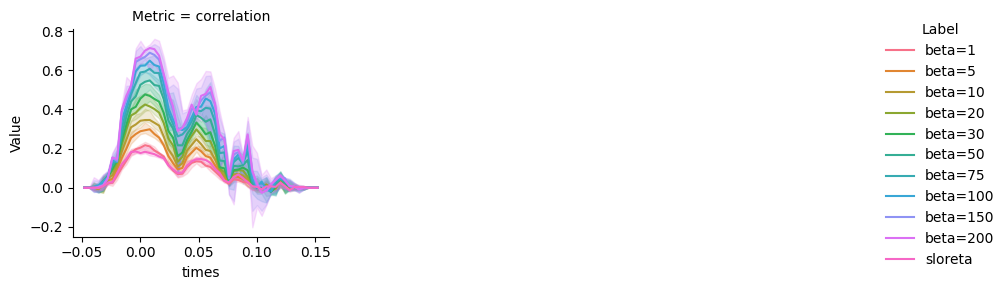

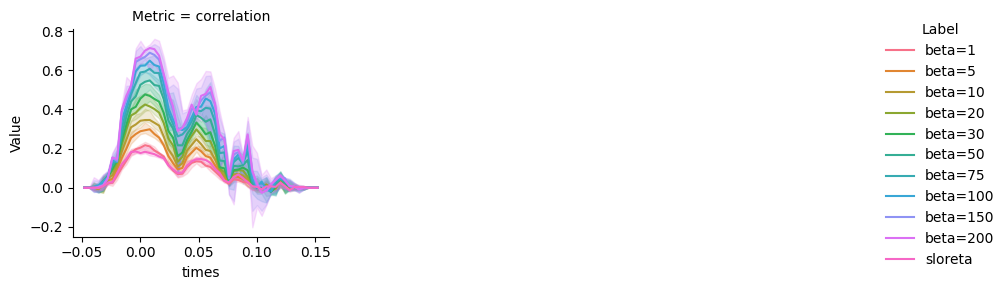

In [4]:
# median +/- IQR across the 10 runs, same convention as the connectome-side
# notebook -- more robust than mean+-SD since the 10 runs are different source
# locations (real heterogeneity), not noise repeats of one signal.
metrics.plot(
    metrics = ["correlation"],
    coord = "times",
    kind = "line",
    estimator = "median",
    errorbar = ("pi", 50),
)

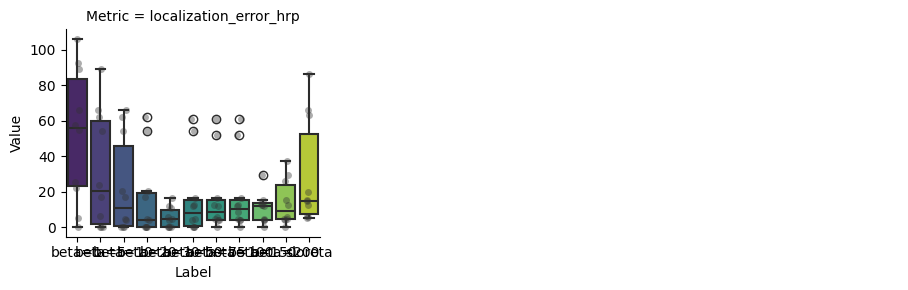

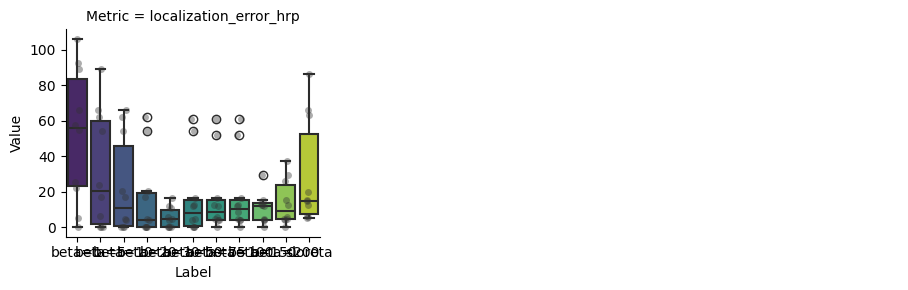

In [5]:
metrics.plot(
    metrics = ["localization_error_hrp"],
    kind = "box",
)

AP by method/beta (mean +/- std across runs 1-10):


ap_hrp               ap_pp           loc_err_hrp           
                   mean       std      mean       std        mean        std
method  beta                                                                
lowpass 1.0    0.294531  0.074650  0.716555  0.111347   52.002687  37.590943
        5.0    0.320021  0.071986  0.721643  0.110907   31.916990  33.106260
        10.0   0.340058  0.068832  0.726385  0.109793   22.827584  27.255512
        20.0   0.366823  0.070568  0.733378  0.106435   16.198843  23.282578
        30.0   0.385928  0.074961  0.739476  0.103293    5.385291   5.886785
        50.0   0.410756  0.086259  0.752650  0.098656   16.506390  22.551488
        75.0   0.430572  0.099135  0.768698  0.092813   17.243509  21.367836
        100.0  0.445281  0.111810  0.781509  0.087681   17.510890  21.225756
        150.0  0.459443  0.137427  0.798151  0.086966   10.800105   8.298801
        200.0  0.461707  0.151882  0.806440  0.093708   13.939962  12.778549
sloreta NaN    0.348898  0.065475  0.730147  0.100044   29.594661  30.243451

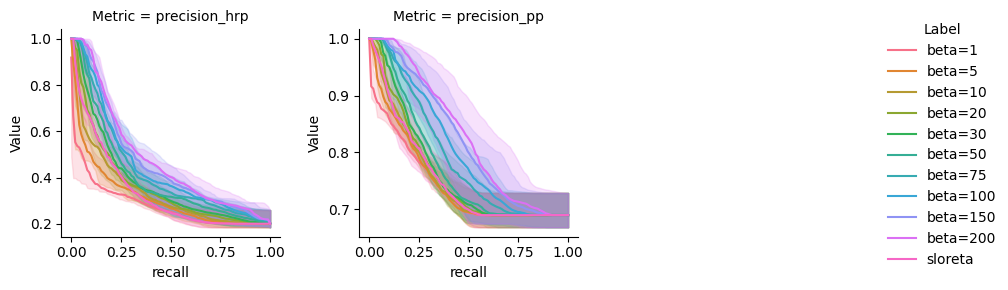

In [6]:
metrics.plot(
    metrics = ["precision_hrp", "precision_pp"],
    coord = "recall",
    kind = "line",
    estimator = "median",
    errorbar = ("pi", 50),
)

print("AP by method/beta (mean +/- std across runs 1-10):")
scalar_df.groupby(["method", "beta"], dropna=False)[["ap_hrp", "ap_pp", "loc_err_hrp"]].agg(["mean", "std"])